# Lab 07: Improving HOG-Based Medical Image Classification Using a Genetic Algorithm
**Dataset:** PneumoniaMNIST (Kaggle: `rijulshr/pneumoniamnist`), binary: normal vs. pneumonia chest X-ray.
**Research question:** Can GA-based feature selection improve the classification performance of HOG features while reducing feature dimensionality?

**Pipeline:** load data -> fixed train/val/test splits -> 128x128 -> HOG (9 orient, 8x8 cells, 2x2 blocks, L2-Hys) -> baseline HOG+SVM (RBF, tuned on val) -> GA feature selection (fitness = val macro-F1 - lambda * selected/total) under several GA settings -> choose the best setting on **validation** -> final **test** evaluation once -> tables, plots, discussion.

Everything below is computed when you run the notebook; no numbers are hard-coded.

## 0. Setup and configuration

In [1]:
import os, time, glob, random, warnings, itertools
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from skimage.feature import hog
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, cohen_kappa_score, matthews_corrcoef, confusion_matrix)
warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED); np.random.seed(SEED)

# ---- configuration -------------------------------------------------------
QUICK = False            # True = tiny smoke test (few images, tiny GA) just to check the code runs
IMG_SIZE = 128
HOG_PARAMS = dict(orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), block_norm='L2-Hys')
LAMBDA = 0.05            # feature-selection penalty weight
GA_FIT_SUBSAMPLE = 1500  # train images used inside GA fitness (speed); final models use ALL train data
GA_GENERATIONS = 15
GA_SETTINGS = {          # at least two GA settings
    'GA-A (pop=16, pm=0.005)': dict(pop=16, pm=0.005, pc=0.8, elite=2, tour=3),
    'GA-B (pop=30, pm=0.010)': dict(pop=30, pm=0.010, pc=0.8, elite=2, tour=3),
    'GA-C (pop=16, pm=0.020)': dict(pop=16, pm=0.020, pc=0.8, elite=2, tour=3),
}
if QUICK:
    GA_GENERATIONS = 3; GA_FIT_SUBSAMPLE = 300
    GA_SETTINGS = {'GA-A (pop=6, pm=0.005)': dict(pop=6, pm=0.005, pc=0.8, elite=1, tour=2),
                   'GA-B (pop=8, pm=0.010)': dict(pop=8, pm=0.010, pc=0.8, elite=1, tour=2)}
os.makedirs('results', exist_ok=True)
print('QUICK =', QUICK)

QUICK = False


## 1. Load the dataset (Task 1)

In [2]:
import kagglehub
path = kagglehub.dataset_download("rijulshr/pneumoniamnist")
print("Path to dataset files:", path)

100%|██████████| 3.39M/3.39M [00:01<00:00, 2.18MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/rijulshr/pneumoniamnist/versions/1


The Kaggle copy of PneumoniaMNIST may be stored as a MedMNIST `.npz` or as image folders. The loader below handles both and prints what it found.

In [3]:
def load_npz(f):
    d = np.load(f)
    keys = list(d.keys()); print('npz keys:', keys)
    g = lambda k: d[k]
    X = {s: g(f'{s}_images') for s in ['train', 'val', 'test']}
    y = {s: g(f'{s}_labels').ravel().astype(int) for s in ['train', 'val', 'test']}
    return X, y

def read_gray(p):
    im = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
    return im

def load_folders(root):
    alias = {'train': 'train', 'val': 'val', 'valid': 'val', 'validation': 'val', 'test': 'test'}
    split_dirs = {}
    for dp, dn, _ in os.walk(root):
        for d in dn:
            if d.lower() in alias and alias[d.lower()] not in split_dirs:
                split_dirs[alias[d.lower()]] = os.path.join(dp, d)
    print('split dirs:', split_dirs)
    classes = None; X, y = {}, {}
    for s, d in split_dirs.items():
        cls = sorted([c for c in os.listdir(d) if os.path.isdir(os.path.join(d, c))])
        classes = classes or cls
        imgs, labs = [], []
        for ci, c in enumerate(classes):
            for p in glob.glob(os.path.join(d, c, '*')):
                im = read_gray(p)
                if im is not None: imgs.append(im); labs.append(ci)
        X[s] = imgs; y[s] = np.array(labs)
    print('classes:', classes)
    return X, y, classes

DATA_ROOT = os.environ.get('LAB_DATA_DIR', path)
npz = glob.glob(os.path.join(DATA_ROOT, '**', '*.npz'), recursive=True)
classes = None
if npz:
    X, y = load_npz(npz[0])
else:
    X, y, classes = load_folders(DATA_ROOT)

# Make sure we have train / val / test. If val is missing, carve a stratified one out of train.
if 'val' not in X:
    idx_tr, idx_va = train_test_split(np.arange(len(y['train'])), test_size=0.15, stratify=y['train'], random_state=SEED)
    X['val'] = [X['train'][i] for i in idx_va]; y['val'] = y['train'][idx_va]
    X['train'] = [X['train'][i] for i in idx_tr]; y['train'] = y['train'][idx_tr]
    print('Validation set was missing -> created from train (15%, stratified).')

for s in ['train', 'val', 'test']:
    print(s, len(y[s]), 'class counts:', np.bincount(y[s]))
CLASS_NAMES = classes or ['normal', 'pneumonia']

npz keys: ['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']
train 3882 class counts: [ 388 3494]
val 524 class counts: [135 389]
test 624 class counts: [234 390]


## 2. Preprocessing and fixed splits (Task 2)
All images -> grayscale, resized to 128x128, scaled to [0,1]. The same fixed train/val/test splits are used for every method.

{'train': (3882, 128, 128), 'val': (524, 128, 128), 'test': (624, 128, 128)}


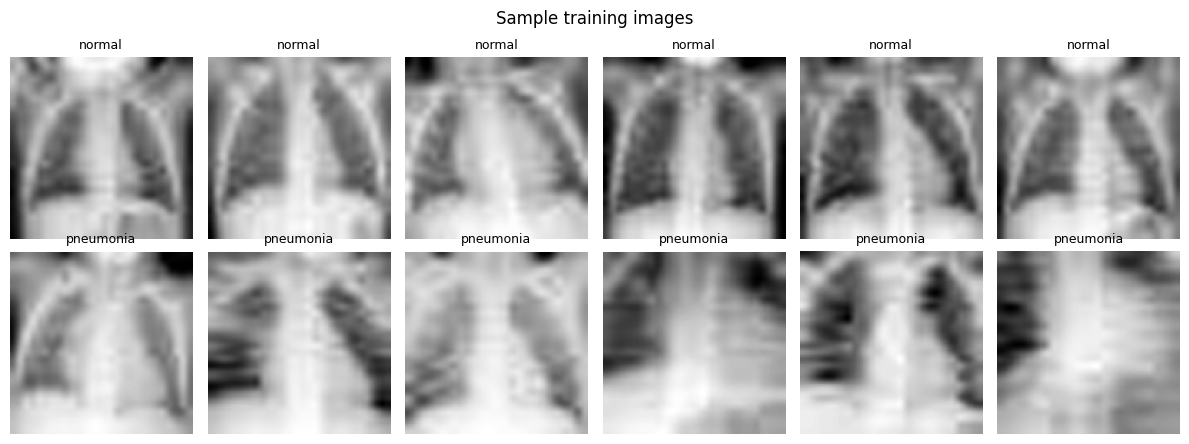

In [4]:
def prep(im):
    im = np.asarray(im)
    if im.ndim == 3: im = im[..., 0] if im.shape[-1] in (1, 3) else im.squeeze()
    im = cv2.resize(im.astype(np.uint8), (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_CUBIC)
    return im.astype(np.float32) / 255.0

if QUICK:   # tiny subset, stratified
    for s, n in [('train', 400), ('val', 120), ('test', 120)]:
        idx = np.random.RandomState(SEED).permutation(len(y[s]))[:n]
        X[s] = [X[s][i] for i in idx]; y[s] = y[s][idx]

IM = {s: np.stack([prep(im) for im in X[s]]) for s in ['train', 'val', 'test']}
Y = {s: np.asarray(y[s]).astype(int) for s in ['train', 'val', 'test']}
print({s: IM[s].shape for s in IM})

fig, ax = plt.subplots(2, 6, figsize=(12, 4.5))
for r, cls in enumerate([0, 1]):
    ids = np.where(Y['train'] == cls)[0][:6]
    for c, i in enumerate(ids):
        ax[r, c].imshow(IM['train'][i], cmap='gray'); ax[r, c].axis('off'); ax[r, c].set_title(CLASS_NAMES[cls], fontsize=9)
plt.suptitle('Sample training images'); plt.tight_layout(); plt.savefig('results/samples.png', dpi=150); plt.show()

### Task 2b: Visualizing HOG Gradient "Edges" of Scans
To verify what geometric edge patterns HOG actually extracts from the chest scans, we can run the HOG descriptor with `visualize=True` on a couple of sample images and plot the localized gradient orientations.

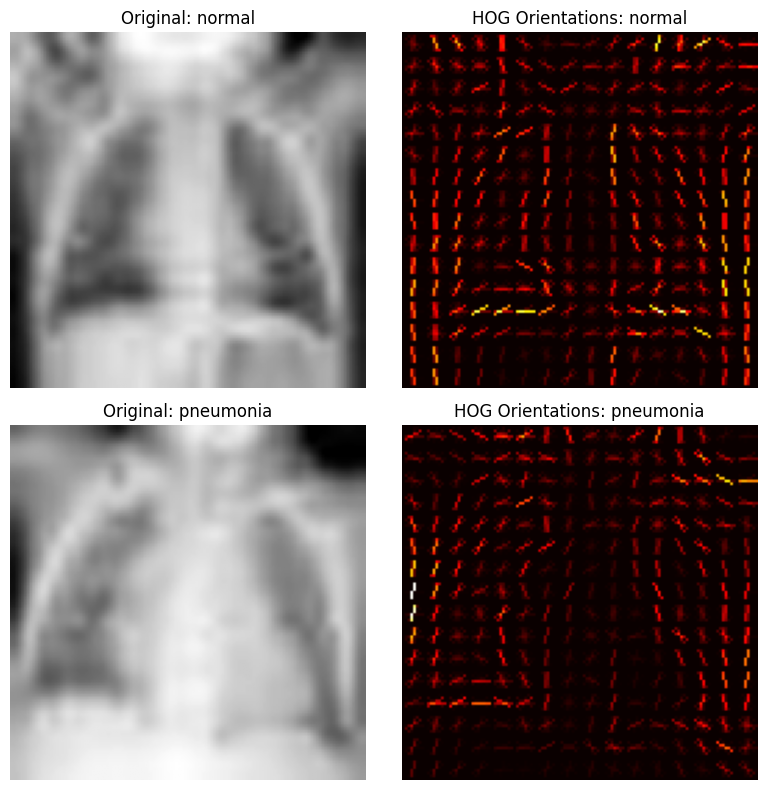

In [20]:
from skimage.feature import hog
import matplotlib.pyplot as plt

# Let's take one normal scan and one pneumonia scan to visualize their HOG representation
fig, axes = plt.subplots(2, 2, figsize=(8, 8))

for i, cls_idx in enumerate([0, 1]):
    # Get first image from this class
    idx = np.where(Y['train'] == cls_idx)[0][0]
    img = IM['train'][idx]

    # Compute HOG and get visualization image
    _, hog_image = hog(img, **HOG_PARAMS, visualize=True)

    # Plot original
    axes[i, 0].imshow(img, cmap='gray')
    axes[i, 0].set_title(f'Original: {CLASS_NAMES[cls_idx]}')
    axes[i, 0].axis('off')

    # Plot HOG gradient edges
    axes[i, 1].imshow(hog_image, cmap='hot')
    axes[i, 1].set_title(f'HOG Orientations: {CLASS_NAMES[cls_idx]}')
    axes[i, 1].axis('off')

plt.tight_layout()
plt.savefig('results/hog_visualizations.png', dpi=150)
plt.show()

## 3. HOG feature extraction (Task 4, Table 1 parameters)

In [5]:
def hog_one(im): return hog(im, **HOG_PARAMS, feature_vector=True)

t0 = time.time()
HOGF = {s: np.array(Parallel(n_jobs=-1)(delayed(hog_one)(im) for im in IM[s])) for s in ['train', 'val', 'test']}
T_HOG = time.time() - t0
N_FEAT = HOGF['train'].shape[1]
print({s: HOGF[s].shape for s in HOGF}, f'| HOG extraction time: {T_HOG:.1f}s | features: {N_FEAT}')

scaler = StandardScaler().fit(HOGF['train'])           # fitted on TRAIN only
F = {s: scaler.transform(HOGF[s]).astype(np.float32) for s in HOGF}

{'train': (3882, 8100), 'val': (524, 8100), 'test': (624, 8100)} | HOG extraction time: 29.7s | features: 8100


### Table 1. Experimental configuration

In [6]:
table1 = pd.DataFrame([
    ['Medical dataset', 'PneumoniaMNIST', 'PneumoniaMNIST'],
    ['Image resolution', f'{IMG_SIZE} x {IMG_SIZE}', f'{IMG_SIZE} x {IMG_SIZE}'],
    ['HOG orientations', HOG_PARAMS['orientations'], HOG_PARAMS['orientations']],
    ['Pixels per cell', '8 x 8', '8 x 8'],
    ['Cells per block', '2 x 2', '2 x 2'],
    ['Block normalization', HOG_PARAMS['block_norm'], HOG_PARAMS['block_norm']],
    ['Feature selection', 'None', 'Genetic Algorithm'],
    ['Classifier', 'SVM', 'SVM'],
    ['SVM kernel', 'RBF', 'RBF'],
    ['Hyperparameter tuning', 'Validation set', 'Validation set'],
    ['Data split', f"Fixed: train {len(Y['train'])} / val {len(Y['val'])} / test {len(Y['test'])}", 'Identical fixed split'],
    ['Random seed', SEED, SEED],
], columns=['Parameter', 'Baseline: HOG + SVM', 'Proposed: GA-HOG + SVM'])
table1.to_csv('results/table1_config.csv', index=False); table1

,Parameter,Baseline: HOG + SVM,Proposed: GA-HOG + SVM
0,Medical dataset,PneumoniaMNIST,PneumoniaMNIST
1,Image resolution,128 x 128,128 x 128
2,HOG orientations,9,9
3,Pixels per cell,8 x 8,8 x 8
4,Cells per block,2 x 2,2 x 2
5,Block normalization,L2-Hys,L2-Hys
6,Feature selection,None,Genetic Algorithm
7,Classifier,SVM,SVM
8,SVM kernel,RBF,RBF
9,Hyperparameter tuning,Validation set,Validation set


## 4. Metrics helper

In [7]:
def specificity_macro(yt, yp):
    cm = confusion_matrix(yt, yp); spec = []
    for k in range(cm.shape[0]):               # one-vs-rest, then macro average
        tn = cm.sum() - cm[k].sum() - cm[:, k].sum() + cm[k, k]
        fp = cm[:, k].sum() - cm[k, k]
        spec.append(tn / (tn + fp) if (tn + fp) else 0.0)
    return float(np.mean(spec))

def all_metrics(yt, yp):
    return {
        'Accuracy (%)': 100 * accuracy_score(yt, yp),
        'Precision (Macro, %)': 100 * precision_score(yt, yp, average='macro', zero_division=0),
        'Recall (Macro, %)': 100 * recall_score(yt, yp, average='macro', zero_division=0),
        'Macro-F1 (%)': 100 * f1_score(yt, yp, average='macro', zero_division=0),
        'Weighted-F1 (%)': 100 * f1_score(yt, yp, average='weighted', zero_division=0),
        'Balanced accuracy (%)': 100 * balanced_accuracy_score(yt, yp),
        'Specificity (Macro, %)': 100 * specificity_macro(yt, yp),
        "Cohen's kappa": cohen_kappa_score(yt, yp),
        'Matthews correlation coefficient': matthews_corrcoef(yt, yp),
    }

def make_svm(Xa, C, gmult):
    gamma = gmult / (Xa.shape[1] * Xa.var())     # gmult = 1 equals sklearn's gamma='scale'
    return SVC(kernel='rbf', C=C, gamma=gamma, class_weight='balanced', random_state=SEED)

def tune_svm(Xtr, ytr, Xva, yva, Cs=(0.5, 2, 8), gms=(0.5, 1, 2)):
    best = None; rows = []
    for C_, g_ in itertools.product(Cs, gms):
        clf = make_svm(Xtr, C_, g_).fit(Xtr, ytr)
        f1 = f1_score(yva, clf.predict(Xva), average='macro'); rows.append((C_, g_, f1))
        if best is None or f1 > best[0]: best = (f1, C_, g_)
    return best, pd.DataFrame(rows, columns=['C', 'gamma_mult', 'val_macroF1'])

## 5. Baseline: HOG + SVM (Task 3)
Hyperparameters (C, gamma) are tuned on the **validation** set only. The test set is not touched here.

In [8]:
t0 = time.time()
(base_f1, base_C, base_g), base_grid = tune_svm(F['train'], Y['train'], F['val'], Y['val'])
base_clf = make_svm(F['train'], base_C, base_g).fit(F['train'], Y['train'])
T_BASE_TRAIN = time.time() - t0
t0 = time.time(); _ = base_clf.predict(F['val']); T_BASE_PRED = time.time() - t0
print(f'Baseline best: C={base_C}, gamma_mult={base_g}, val macro-F1={100*base_f1:.2f}% | tune+train time {T_BASE_TRAIN:.1f}s')
base_grid

Baseline best: C=0.5, gamma_mult=0.5, val macro-F1=96.01% | tune+train time 305.8s


,C,gamma_mult,val_macroF1
0,0.5,0.5,0.960088
1,0.5,1.0,0.949366
2,0.5,2.0,0.925633
3,2.0,0.5,0.959078
4,2.0,1.0,0.945290
5,2.0,2.0,0.895462
6,8.0,0.5,0.942839
7,8.0,1.0,0.939754
8,8.0,2.0,0.892383


## 6. Genetic Algorithm for feature selection (Tasks 5 and 6)

- **Chromosome:** binary mask of length = number of HOG features (1 = keep).
- **Initialisation:** each individual has a random keep-density in [0.2, 0.6].
- **Fitness:** `validation macro-F1 - LAMBDA * (selected / total)`. SVM is trained on a stratified train subsample for speed (C, gamma taken from the baseline); validation is the full val set.
- **Selection:** tournament. **Crossover:** uniform. **Mutation:** per-bit flip. **Elitism:** best individuals carried over.

In [9]:
rng_sub = np.random.RandomState(SEED)
if GA_FIT_SUBSAMPLE < len(Y['train']):
    sub_idx, _ = train_test_split(np.arange(len(Y['train'])), train_size=GA_FIT_SUBSAMPLE, stratify=Y['train'], random_state=SEED)
else:
    sub_idx = np.arange(len(Y['train']))
Xsub, ysub = F['train'][sub_idx], Y['train'][sub_idx]

def fitness(mask):
    k = int(mask.sum())
    if k < 10: return -1.0, 0.0
    Xa = Xsub[:, mask.astype(bool)]
    clf = make_svm(Xa, base_C, base_g).fit(Xa, ysub)
    f1 = f1_score(Y['val'], clf.predict(F['val'][:, mask.astype(bool)]), average='macro')
    return f1 - LAMBDA * k / N_FEAT, f1

def run_ga(pop, pm, pc, elite, tour, generations, seed=SEED, verbose=True):
    rng = np.random.RandomState(seed)
    dens = rng.uniform(0.2, 0.6, size=pop)
    P = (rng.rand(pop, N_FEAT) < dens[:, None]).astype(np.uint8)
    hist = dict(best_fit=[], mean_fit=[], best_nfeat=[], best_f1=[])
    cache = {}
    t0 = time.time()
    for g in range(generations + 1):
        todo = [i for i in range(pop) if P[i].tobytes() not in cache]
        res = Parallel(n_jobs=-1, backend='threading')(delayed(fitness)(P[i]) for i in todo)
        for i, r in zip(todo, res): cache[P[i].tobytes()] = r
        fit = np.array([cache[P[i].tobytes()][0] for i in range(pop)])
        f1s = np.array([cache[P[i].tobytes()][1] for i in range(pop)])
        b = int(fit.argmax())
        hist['best_fit'].append(fit[b]); hist['mean_fit'].append(fit.mean())
        hist['best_nfeat'].append(int(P[b].sum())); hist['best_f1'].append(f1s[b])
        if verbose: print(f'gen {g:2d} | best fit {fit[b]:.4f} (val F1 {f1s[b]:.4f}, {int(P[b].sum())} feats) | mean {fit.mean():.4f} | {time.time()-t0:.0f}s')
        if g == generations: break
        order = np.argsort(-fit)
        new = [P[i].copy() for i in order[:elite]]
        while len(new) < pop:
            def pick():
                c = rng.choice(pop, tour, replace=False); return P[c[fit[c].argmax()]]
            p1, p2 = pick(), pick()
            if rng.rand() < pc:                                   # uniform crossover
                m = rng.rand(N_FEAT) < 0.5
                c1, c2 = np.where(m, p1, p2), np.where(m, p2, p1)
            else:
                c1, c2 = p1.copy(), p2.copy()
            for c in (c1, c2):
                flip = rng.rand(N_FEAT) < pm                      # bit-flip mutation
                c[flip] = 1 - c[flip]
                if len(new) < pop: new.append(c.astype(np.uint8))
        P = np.stack(new)
    best_mask = P[int(np.argmax(fit))].astype(bool)
    return best_mask, hist, time.time() - t0

## 7. Run the GA under several settings (Task 6, GA experiments)

In [10]:
GA_RESULTS = {}
for name, cfg in GA_SETTINGS.items():
    print('\n====', name, '====')
    mask, hist, t_ga = run_ga(**cfg, generations=GA_GENERATIONS)
    GA_RESULTS[name] = dict(mask=mask, hist=hist, time=t_ga, cfg=cfg)
    np.save(f"results/mask_{name.split(' ')[0]}.npy", mask)


==== GA-A (pop=16, pm=0.005) ====
gen  0 | best fit 0.9392 (val F1 0.9499, 1728 feats) | mean 0.9295 | 34s
gen  1 | best fit 0.9398 (val F1 0.9525, 2062 feats) | mean 0.9339 | 56s
gen  2 | best fit 0.9415 (val F1 0.9551, 2195 feats) | mean 0.9378 | 75s
gen  3 | best fit 0.9420 (val F1 0.9549, 2084 feats) | mean 0.9372 | 91s
gen  4 | best fit 0.9446 (val F1 0.9575, 2095 feats) | mean 0.9378 | 107s
gen  5 | best fit 0.9446 (val F1 0.9575, 2095 feats) | mean 0.9395 | 126s
gen  6 | best fit 0.9448 (val F1 0.9575, 2057 feats) | mean 0.9412 | 145s
gen  7 | best fit 0.9497 (val F1 0.9625, 2074 feats) | mean 0.9437 | 164s
gen  8 | best fit 0.9497 (val F1 0.9625, 2074 feats) | mean 0.9447 | 184s
gen  9 | best fit 0.9497 (val F1 0.9625, 2074 feats) | mean 0.9471 | 203s
gen 10 | best fit 0.9497 (val F1 0.9625, 2074 feats) | mean 0.9485 | 222s
gen 11 | best fit 0.9497 (val F1 0.9625, 2074 feats) | mean 0.9479 | 242s
gen 12 | best fit 0.9497 (val F1 0.9625, 2074 feats) | mean 0.9475 | 262s
gen 13 

## 8. Train the final SVM on the selected features and compare GA settings on **validation** (Task 7)
Model selection uses validation data only. Each GA setting gets its own SVM (C, gamma re-tuned on validation using the selected features, trained on the full train set).

In [11]:
rows = []
for name, r in GA_RESULTS.items():
    m = r['mask']; t0 = time.time()
    (f1v, Cb, gb), _ = tune_svm(F['train'][:, m], Y['train'], F['val'][:, m], Y['val'])
    clf = make_svm(F['train'][:, m], Cb, gb).fit(F['train'][:, m], Y['train'])
    r.update(clf=clf, C=Cb, g=gb, val_f1=f1v, t_final=time.time() - t0)
    rows.append([name, r['cfg']['pop'], r['cfg']['pm'], int(m.sum()), 100 * (1 - m.sum() / N_FEAT),
                 100 * r['hist']['best_fit'][-1], 100 * f1v, r['time'], r['time'] + r['t_final']])
ga_cmp = pd.DataFrame(rows, columns=['GA setting', 'Population', 'Mutation prob.', 'Selected features',
        'Reduction (%)', 'Best GA fitness (x100)', 'Val macro-F1 (%) (retuned SVM)', 'GA time (s)', 'GA + final SVM time (s)'])
ga_cmp.to_csv('results/table3_ga_settings_validation.csv', index=False)
print(f'Baseline validation macro-F1: {100*base_f1:.2f}% with {N_FEAT} features')
ga_cmp.round(3)

Baseline validation macro-F1: 96.01% with 8100 features


,GA setting,Population,Mutation prob.,Selected features,Reduction (%),Best GA fitness (x100),Val macro-F1 (%) (retuned SVM),GA time (s),GA + final SVM time (s)
0,"GA-A (pop=16, pm=0.005)",16,0.005,2074,74.395,94.969,95.685,319.052,387.649
1,"GA-B (pop=30, pm=0.010)",30,0.010,2530,68.765,95.688,96.508,782.948,867.709
2,"GA-C (pop=16, pm=0.020)",16,0.020,2663,67.123,95.121,96.491,373.242,467.101


In [12]:
# Model selection (validation only): highest validation macro-F1; ties broken by fewer features
BEST = max(GA_RESULTS, key=lambda n: (round(GA_RESULTS[n]['val_f1'], 6), -int(GA_RESULTS[n]['mask'].sum())))
print('Selected GA setting:', BEST)

Selected GA setting: GA-B (pop=30, pm=0.010)


## 9. Final test-set evaluation (run once, after model selection)

In [13]:
mb = GA_RESULTS[BEST]['mask']; ga_clf = GA_RESULTS[BEST]['clf']

t0 = time.time(); yp_base = base_clf.predict(F['test']); T_BASE_TEST = time.time() - t0
t0 = time.time(); yp_ga = ga_clf.predict(F['test'][:, mb]); T_GA_TEST = time.time() - t0

M_base, M_ga = all_metrics(Y['test'], yp_base), all_metrics(Y['test'], yp_ga)
table2 = pd.DataFrame({'HOG + SVM (Baseline)': M_base, 'GA-HOG + SVM (Proposed)': M_ga})
table2['Improvement'] = table2['GA-HOG + SVM (Proposed)'] - table2['HOG + SVM (Baseline)']
table2.index.name = 'Metric'
table2.round(3).to_csv('results/table2_main_comparison.csv')
print('Test set, GA setting:', BEST)
table2.round(3)

Test set, GA setting: GA-B (pop=30, pm=0.010)


,HOG + SVM (Baseline),GA-HOG + SVM (Proposed),Improvement
Metric,,,
Accuracy (%),84.776,84.455,-0.321
"Precision (Macro, %)",89.101,88.913,-0.188
"Recall (Macro, %)",80.043,79.615,-0.427
Macro-F1 (%),82.054,81.622,-0.432
Weighted-F1 (%),83.801,83.426,-0.375
Balanced accuracy (%),80.043,79.615,-0.427
"Specificity (Macro, %)",80.043,79.615,-0.427
Cohen's kappa,0.649,0.641,-0.008
Matthews correlation coefficient,0.685,0.679,-0.007


### Table 4. Computational cost and dimensionality

In [14]:
t_ga = GA_RESULTS[BEST]['time']; t_fin = GA_RESULTS[BEST]['t_final']
table4 = pd.DataFrame({
  'HOG + SVM (Baseline)':   [N_FEAT, T_HOG, 0.0, T_BASE_TRAIN, T_HOG + T_BASE_TRAIN, T_BASE_TEST, 1000 * T_BASE_TEST / len(Y['test'])],
  'GA-HOG + SVM (Proposed)':[int(mb.sum()), T_HOG, t_ga, t_fin, T_HOG + t_ga + t_fin, T_GA_TEST, 1000 * T_GA_TEST / len(Y['test'])],
}, index=['Number of features', 'HOG extraction (s)', 'GA search (s)', 'SVM tuning + training (s)',
          'Total pipeline time (s)', 'Test prediction time (s)', 'Prediction time per image (ms)'])
table4.round(3).to_csv('results/table4_cost.csv'); table4.round(3)

,HOG + SVM (Baseline),GA-HOG + SVM (Proposed)
Number of features,8100.000,2530.000
HOG extraction (s),29.708,29.708
GA search (s),0.000,782.948
SVM tuning + training (s),305.806,84.761
Total pipeline time (s),335.513,897.417
Test prediction time (s),6.001,1.482
Prediction time per image (ms),9.617,2.376


## 10. Plots (Task 9)

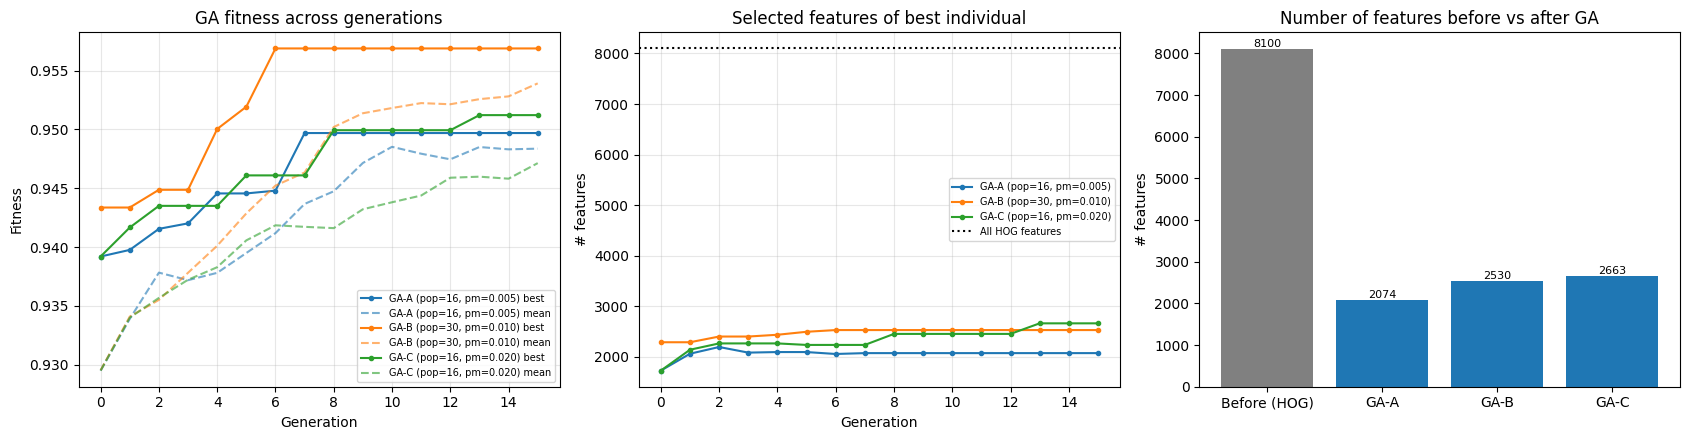

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for name, r in GA_RESULTS.items():
    h = r['hist']; g = np.arange(len(h['best_fit']))
    l, = ax[0].plot(g, h['best_fit'], marker='o', ms=3, label=f'{name} best')
    ax[0].plot(g, h['mean_fit'], ls='--', color=l.get_color(), alpha=.6, label=f'{name} mean')
    ax[1].plot(g, h['best_nfeat'], marker='o', ms=3, label=name)
ax[0].set(title='GA fitness across generations', xlabel='Generation', ylabel='Fitness'); ax[0].legend(fontsize=7); ax[0].grid(alpha=.3)
ax[1].axhline(N_FEAT, color='k', ls=':', label='All HOG features')
ax[1].set(title='Selected features of best individual', xlabel='Generation', ylabel='# features'); ax[1].legend(fontsize=7); ax[1].grid(alpha=.3)
names = ['Before (HOG)'] + [n.split(' ')[0] for n in GA_RESULTS]
vals = [N_FEAT] + [int(r['mask'].sum()) for r in GA_RESULTS.values()]
bars = ax[2].bar(names, vals, color=['gray'] + ['tab:blue'] * len(GA_RESULTS))
for b, v in zip(bars, vals): ax[2].text(b.get_x() + b.get_width() / 2, v, str(v), ha='center', va='bottom', fontsize=8)
ax[2].set(title='Number of features before vs after GA', ylabel='# features')
plt.tight_layout(); plt.savefig('results/ga_fitness_and_features.png', dpi=150); plt.show()

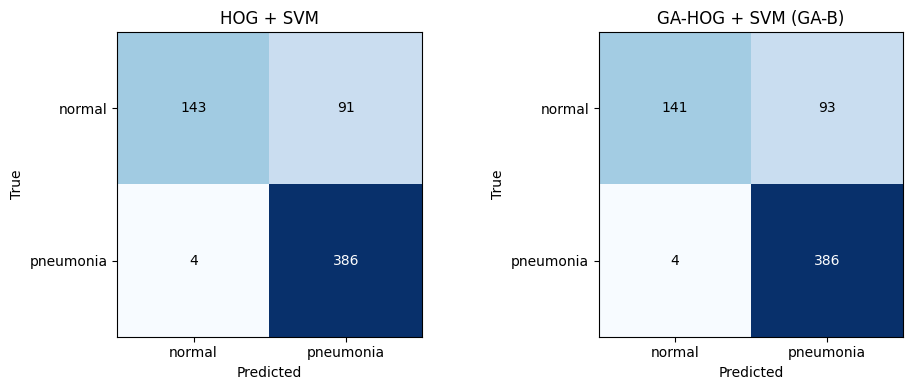

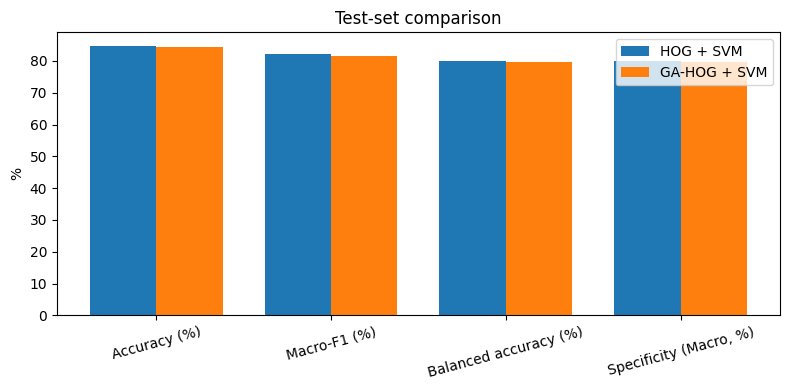

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, yp, t in zip(ax, [yp_base, yp_ga], ['HOG + SVM', f'GA-HOG + SVM ({BEST.split(" ")[0]})']):
    cm = confusion_matrix(Y['test'], yp); a.imshow(cm, cmap='Blues')
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        a.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black')
    a.set(title=t, xlabel='Predicted', ylabel='True', xticks=range(len(CLASS_NAMES)), yticks=range(len(CLASS_NAMES)),
          xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.tight_layout(); plt.savefig('results/confusion_matrices.png', dpi=150); plt.show()

keys = ['Accuracy (%)', 'Macro-F1 (%)', 'Balanced accuracy (%)', 'Specificity (Macro, %)']
x = np.arange(len(keys)); w = .38
plt.figure(figsize=(8, 4))
plt.bar(x - w/2, [M_base[k] for k in keys], w, label='HOG + SVM'); plt.bar(x + w/2, [M_ga[k] for k in keys], w, label='GA-HOG + SVM')
plt.xticks(x, keys, rotation=15); plt.ylabel('%'); plt.title('Test-set comparison'); plt.legend(); plt.tight_layout()
plt.savefig('results/metric_comparison.png', dpi=150); plt.show()

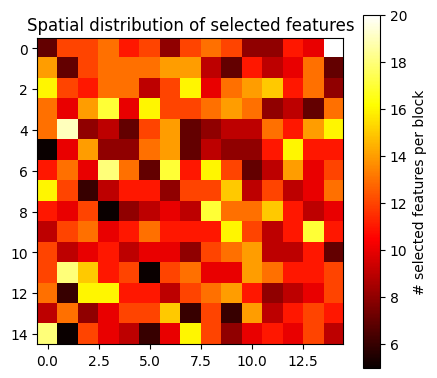

In [17]:
# Where do the selected HOG features live in the image? (each 128x128 image -> 15x15 blocks x 36 values)
nb_ = IMG_SIZE // 8 - 1
heat = mb.reshape(nb_, nb_, 2, 2, HOG_PARAMS['orientations']).sum(axis=(2, 3, 4))
plt.figure(figsize=(4.5, 4)); plt.imshow(heat, cmap='hot'); plt.colorbar(label='# selected features per block')
plt.title('Spatial distribution of selected features'); plt.tight_layout(); plt.savefig('results/selected_feature_map.png', dpi=150); plt.show()

## 11. Auto-generated summary of the actual results

In [18]:
d = table2['Improvement']
verdict = 'improved' if d['Macro-F1 (%)'] > 0 else ('matched' if d['Macro-F1 (%)'] == 0 else 'did not improve')
red = 100 * (1 - mb.sum() / N_FEAT)
print(f"Selected GA setting (by validation): {BEST}")
print(f"Features: {N_FEAT} -> {int(mb.sum())} ({red:.1f}% reduction)")
print(f"Test macro-F1: {M_base['Macro-F1 (%)']:.2f}% -> {M_ga['Macro-F1 (%)']:.2f}% ({d['Macro-F1 (%)']:+.2f} pts); GA {verdict} macro-F1.")
print(f"Test accuracy: {M_base['Accuracy (%)']:.2f}% -> {M_ga['Accuracy (%)']:.2f}% ({d['Accuracy (%)']:+.2f} pts); balanced acc: {d['Balanced accuracy (%)']:+.2f} pts")
print(f"Total pipeline time: {table4.loc['Total pipeline time (s)','HOG + SVM (Baseline)']:.0f}s -> {table4.loc['Total pipeline time (s)','GA-HOG + SVM (Proposed)']:.0f}s; "
      f"prediction per image: {table4.loc['Prediction time per image (ms)','HOG + SVM (Baseline)']:.3f} ms -> {table4.loc['Prediction time per image (ms)','GA-HOG + SVM (Proposed)']:.3f} ms")
print(f"Test set has {len(Y['test'])} images, so a difference of one image is about {100/len(Y['test']):.2f} accuracy points; small gaps may be noise.")

Selected GA setting (by validation): GA-B (pop=30, pm=0.010)
Features: 8100 -> 2530 (68.8% reduction)
Test macro-F1: 82.05% -> 81.62% (-0.43 pts); GA did not improve macro-F1.
Test accuracy: 84.78% -> 84.46% (-0.32 pts); balanced acc: -0.43 pts
Total pipeline time: 336s -> 897s; prediction per image: 9.617 ms -> 2.376 ms
Test set has 624 images, so a difference of one image is about 0.16 accuracy points; small gaps may be noise.


## 12. Discussion (Task 10)
*Read the numbers printed above and in Tables 2-4, then adapt the points below to your actual results.*

**Did GA improve performance?** Compare the Improvement column of Table 2. A change of only a few test images is within sampling noise; the validation-vs-test gap and the confusion matrices help judge this. If the GA gain on validation is larger than on test, part of it is overfitting the GA to the validation set (the GA directly optimises validation F1).

**Dimensionality.** The HOG vector has 8100 dimensions (15x15 blocks x 36). The GA keeps a subset (Table 3/4, bar plot), which lowers SVM prediction cost and memory and shows which image regions/orientations matter (selected-feature map).

**Strengths.** Wrapper-style search directly optimises the final metric and can remove redundant or noisy HOG cells; the penalty term gives an explicit accuracy-vs-size trade-off; the result is interpretable.

**Limitations.** Very high-dimensional search space (8100 bits) with small populations and few generations means the search is far from exhaustive; fitness is noisy because it is trained on a subsample; results depend on the seed and on the penalty weight; the GA can overfit the validation set; PneumoniaMNIST is upscaled from 28x28, which limits how much fine HOG detail exists.

**Computational cost.** Each fitness evaluation trains an SVM, so GA cost is roughly population x generations SVM fits (Table 4, "GA search"). This is a one-time training cost; inference is cheaper afterwards. Larger populations or higher mutation (Table 3) cost more time and do not always give a better solution.

**Possible improvements.** Filter-based pre-selection before the GA, multiple seeds with mean +/- std, larger populations/generations, cross-validation inside the fitness, or a lighter classifier inside the fitness.

## 13. Final tables (copy into your report)

In [19]:
pd.set_option('display.width', 200)
print('Table 1. Configuration'); display(table1)
print('Table 2. Main performance comparison (TEST set)'); display(table2.round(3))
print('Table 3. GA settings compared on VALIDATION'); display(ga_cmp.round(3))
print('Table 4. Computational cost'); display(table4.round(3))

Table 1. Configuration


,Parameter,Baseline: HOG + SVM,Proposed: GA-HOG + SVM
0,Medical dataset,PneumoniaMNIST,PneumoniaMNIST
1,Image resolution,128 x 128,128 x 128
2,HOG orientations,9,9
3,Pixels per cell,8 x 8,8 x 8
4,Cells per block,2 x 2,2 x 2
5,Block normalization,L2-Hys,L2-Hys
6,Feature selection,None,Genetic Algorithm
7,Classifier,SVM,SVM
8,SVM kernel,RBF,RBF
9,Hyperparameter tuning,Validation set,Validation set


Table 2. Main performance comparison (TEST set)


,HOG + SVM (Baseline),GA-HOG + SVM (Proposed),Improvement
Metric,,,
Accuracy (%),84.776,84.455,-0.321
"Precision (Macro, %)",89.101,88.913,-0.188
"Recall (Macro, %)",80.043,79.615,-0.427
Macro-F1 (%),82.054,81.622,-0.432
Weighted-F1 (%),83.801,83.426,-0.375
Balanced accuracy (%),80.043,79.615,-0.427
"Specificity (Macro, %)",80.043,79.615,-0.427
Cohen's kappa,0.649,0.641,-0.008
Matthews correlation coefficient,0.685,0.679,-0.007


Table 3. GA settings compared on VALIDATION


,GA setting,Population,Mutation prob.,Selected features,Reduction (%),Best GA fitness (x100),Val macro-F1 (%) (retuned SVM),GA time (s),GA + final SVM time (s)
0,"GA-A (pop=16, pm=0.005)",16,0.005,2074,74.395,94.969,95.685,319.052,387.649
1,"GA-B (pop=30, pm=0.010)",30,0.010,2530,68.765,95.688,96.508,782.948,867.709
2,"GA-C (pop=16, pm=0.020)",16,0.020,2663,67.123,95.121,96.491,373.242,467.101


Table 4. Computational cost


,HOG + SVM (Baseline),GA-HOG + SVM (Proposed)
Number of features,8100.000,2530.000
HOG extraction (s),29.708,29.708
GA search (s),0.000,782.948
SVM tuning + training (s),305.806,84.761
Total pipeline time (s),335.513,897.417
Test prediction time (s),6.001,1.482
Prediction time per image (ms),9.617,2.376
